# Synthetic DAS benchmark generator

# Cell 1: generator

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

BASE = dict(fs=200, W=512, S=128, dx=1.0,
            noise_std=1.0, cm_std=0.5, drift_amp=1.5,
            traffic_p=0.6, traffic_amp=2.0, spike_p=0.15, bad_ch_p=0.05)
SITES = {
    "A": dict(BASE),
    "B": dict(BASE, noise_std=1.6, cm_std=0.9, drift_amp=2.5, traffic_p=0.9, traffic_amp=3.0),  # shor wala site
    "C": dict(BASE, noise_std=0.8, cm_std=0.3, drift_amp=0.8, traffic_p=0.2,
              spike_p=0.3, bad_ch_p=0.15),                                                      # shaant, par kharab channels
}

def bandlimited(rng, n, fs, f_lo, f_hi, size=None):
    shape = (n,) if size is None else (n, size)
    F = np.fft.rfft(rng.standard_normal(shape), axis=0)
    f = np.fft.rfftfreq(n, 1 / fs)
    m = ((f >= f_lo) & (f <= f_hi)).astype(float)
    F = F * (m if size is None else m[:, None])
    y = np.fft.irfft(F, n=n, axis=0)
    return y / (y.std() + 1e-12)

def ricker(t, f0):
    a = (np.pi * f0 * t) ** 2
    return (1 - 2 * a) * np.exp(-a)

def smooth_profile(rng, S, width):
    k = np.exp(-0.5 * (np.arange(-3 * width, 3 * width + 1) / width) ** 2)
    g = np.convolve(rng.standard_normal(S + 6 * width), k, mode="valid")[:S]
    return (g - g.mean()) / (g.std() + 1e-12)

def gen_window(rng, cfg, leak=False, snr_db=None):
    W, S, fs = cfg["W"], cfg["S"], cfg["fs"]
    t = np.arange(W) / fs
    ch = np.arange(S)
    X = cfg["noise_std"] * rng.standard_normal((W, S))
    X *= np.clip(1 + 0.2 * rng.standard_normal(S), 0.5, None)[None, :]          # channel gain
    X += cfg["cm_std"] * bandlimited(rng, W, fs, 0.5, 20)[:, None]               # common-mode
    X += (cfg["drift_amp"] * np.sin(2 * np.pi * rng.uniform(0.02, 0.1) * t + rng.uniform(0, 2 * np.pi))[:, None]
          * (1 + 0.5 * smooth_profile(rng, S, 20))[None, :])                     # temperature drift
    if rng.random() < cfg["traffic_p"]:                                          # gadiyan
        for _ in range(rng.integers(1, 4)):
            v, d = rng.uniform(10, 60), rng.choice([-1, 1])
            t0, c0, f0 = rng.uniform(0, W / fs), rng.uniform(0, S), rng.uniform(4, 15)
            tc = t0 + d * (ch - c0) * cfg["dx"] / v
            X += (cfg["traffic_amp"] * rng.uniform(0.5, 1.5) * ricker(t[:, None] - tc[None, :], f0)
                  * np.exp(-(((ch - c0) / (S / 2)) ** 2))[None, :])
    if rng.random() < cfg["spike_p"]:                                            # glitches
        for _ in range(rng.integers(1, 4)):
            X[rng.integers(0, W), rng.integers(0, S)] += rng.choice([-1, 1]) * rng.uniform(5, 10) * cfg["noise_std"]
    X[:, rng.random(S) < cfg["bad_ch_p"]] *= 3                                   # kharab channels

    mask, info = np.zeros(S, bool), dict(kind="none", c0=np.nan, sigma=np.nan, onset_s=np.nan, snr_db=np.nan)
    if leak:
        kind = rng.choice(["lowfreq", "burst", "both"], p=[0.4, 0.3, 0.3])
        c0, sig, onset = rng.uniform(0.15 * S, 0.85 * S), rng.uniform(3, 12), rng.uniform(0.1, 0.6) * W / fs
        g = np.exp(-0.5 * ((ch - c0) / sig) ** 2)
        tt = np.clip(t - onset, 0, None)
        on = (t >= onset).astype(float)
        L = np.zeros((W, S))
        if kind in ("lowfreq", "both"):
            env = on * (1 - np.exp(-tt / 0.2)) * np.exp(-tt / (3 * rng.uniform(0.5, 2.0)))
            L += (env * np.sin(2 * np.pi * rng.uniform(0.7, 5.0) * tt + rng.uniform(0, 2 * np.pi)))[:, None] * g[None, :]
        if kind in ("burst", "both"):
            L += 0.7 * bandlimited(rng, W, fs, 20, 80, size=S) * (on * np.exp(-tt / rng.uniform(0.3, 1.0)))[:, None] * g[None, :]
        act = np.abs(L) > 0.1 * np.abs(L).max()
        snr = rng.uniform(-5, 15) if snr_db is None else snr_db
        X += L * (cfg["noise_std"] * 10 ** (snr / 20) / np.sqrt((L[act] ** 2).mean()))
        mask = g > 0.25
        info = dict(kind=kind, c0=c0, sigma=sig, onset_s=onset, snr_db=snr)
    return X.astype(np.float32), mask, info

def make_dataset(site, n_norm, n_leak, seed):
    rng, cfg = np.random.default_rng(seed), SITES[site]
    flags = np.r_[np.zeros(n_norm, int), np.ones(n_leak, int)]
    rng.shuffle(flags)
    Xs, Ms, meta = [], [], []
    for y in flags:
        x, m, info = gen_window(rng, cfg, bool(y))
        Xs.append(x); Ms.append(m); meta.append(dict(label=int(y), site=site, **info))
    return np.stack(Xs), np.stack(Ms), pd.DataFrame(meta)

# Cell 2: Make splits (In start keep it small, memory ~600 MB)

In [2]:
N = dict(train=600, val=150, test_norm=250, test_leak=250)
X_tr, _, m_tr   = make_dataset("A", N["train"], 0, seed=1)          # sirf normal
X_val, _, m_val = make_dataset("A", N["val"], 0, seed=2)            # sirf normal
tests = {s: make_dataset(s, N["test_norm"], N["test_leak"], seed=10 + i)
         for i, s in enumerate("ABC")}
print("train", X_tr.shape, "| tests:", {s: v[0].shape for s, v in tests.items()})
print("memory ~", (X_tr.nbytes + X_val.nbytes + sum(v[0].nbytes for v in tests.values())) / 1e6, "MB")

train (600, 512, 128) | tests: {'A': (500, 512, 128), 'B': (500, 512, 128), 'C': (500, 512, 128)}
memory ~ 589.824 MB


# Cell 3: See how data looks

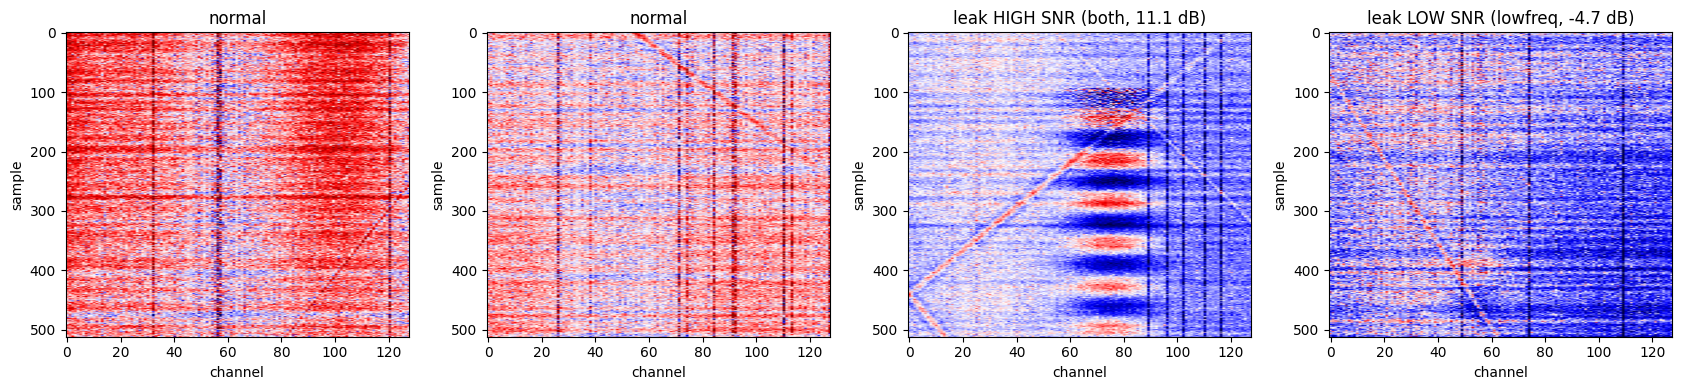

In [3]:
Xa, Ma, meta_a = tests["A"]
idx = [np.where(meta_a.label == 0)[0][0], np.where(meta_a.label == 0)[0][1]]
hi = meta_a[(meta_a.label == 1) & (meta_a.snr_db > 10)].index[0]
lo = meta_a[(meta_a.label == 1) & (meta_a.snr_db < 0)].index[0]
fig, ax = plt.subplots(1, 4, figsize=(17, 4))
for a, i, ttl in zip(ax, idx + [hi, lo], ["normal", "normal", "leak HIGH SNR", "leak LOW SNR"]):
    c = np.percentile(np.abs(Xa[i]), 99)
    a.imshow(Xa[i], aspect="auto", cmap="seismic", vmin=-c, vmax=c)
    r = meta_a.loc[i]
    a.set_title(ttl if r.label == 0 else f"{ttl} ({r.kind}, {r.snr_db:.1f} dB)")
    a.set_xlabel("channel"); a.set_ylabel("sample")
plt.tight_layout(); plt.show()

# Cell 4: Sanity check. Is the task neither too easy nor impossible? (simple PCA baseline)

In [4]:
def auroc(y, s):
    r = np.empty(len(s)); r[np.argsort(s)] = np.arange(1, len(s) + 1)
    n1 = y.sum(); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

mu = X_tr.mean(axis=(0, 1), keepdims=True); sd = X_tr.std(axis=(0, 1), keepdims=True) + 1e-8
prep = lambda X: ((X - mu) / sd).reshape(len(X), -1)
Z = prep(X_tr); zm = Z.mean(0); Zc = Z - zm
w, U = np.linalg.eigh(Zc @ Zc.T)
k = 20; top = np.argsort(w)[::-1][:k]
V = Zc.T @ U[:, top] / np.sqrt(w[top])
def score(X):
    z = prep(X) - zm
    return ((z - (z @ V) @ V.T) ** 2).mean(1)

for s, (X, M, meta) in tests.items():
    sc, y = score(X), meta.label.values
    row = {"all": auroc(y, sc)}
    for lo_, hi_ in [(-5, 0), (0, 5), (5, 10), (10, 15.01)]:
        sel = (y == 0) | ((meta.snr_db >= lo_) & (meta.snr_db < hi_)).values
        row[f"{lo_}..{hi_:.0f} dB"] = auroc(y[sel], sc[sel])
    print(f"site {s}:", {k_: round(v, 3) for k_, v in row.items()})

site A: {'all': 0.717, '-5..0 dB': 0.503, '0..5 dB': 0.627, '5..10 dB': 0.797, '10..15 dB': 0.931}
site B: {'all': 0.688, '-5..0 dB': 0.498, '0..5 dB': 0.563, '5..10 dB': 0.778, '10..15 dB': 0.938}
site C: {'all': 0.712, '-5..0 dB': 0.563, '0..5 dB': 0.635, '5..10 dB': 0.716, '10..15 dB': 0.916}


In [5]:
thr = np.quantile(score(X_val), 0.99)          # site A ke normal data se bani threshold
for s, (X, M, meta) in tests.items():
    sc, y = score(X), meta.label.values
    print(s, "FAR", round((sc[y == 0] > thr).mean(), 3), " recall", round((sc[y == 1] > thr).mean(), 3))

A FAR 0.024  recall 0.192
B FAR 1.0  recall 1.0
C FAR 0.0  recall 0.1
